# 06 — ML Evaluation & Failure Analysis
**Part D | Milestone 6**

Question: how well do the models predict drift on a sequence they never saw, and where and why do they fail?

All numbers here are read from files written by `python scripts/evaluate.py`:
`results/metrics/<target>.csv`, `results/metrics/<target>_importance.csv`, `results/predictions/<target>.csv`. Figures come from `src/vio_drift/evaluation/plots.py`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import joblib
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vio_drift.models.ml.data import load_dataset, load_splits, split_xy, fold_frames
from vio_drift.models.ml.registry import model_specs, MODEL_NAMES

ROOT = Path.cwd().parent
config = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())
sequences = config["data"]["sequences"]
processed = ROOT / config["data"]["processed_dir"]
seed = int(config["seed"])
MODELS_DIR = ROOT / "models" / "ml"
METRICS = ROOT / "results" / "metrics"

TARGET = "err_mag_m"
df = load_dataset(processed, sequences, target=TARGET)
folds = load_splits(processed / "splits.json")

def saved(fold_id, model, target=TARGET):
    """Load a model written by scripts/train_ml.py."""
    return joblib.load(MODELS_DIR / f"{target}__{fold_id}__{model}.joblib")

print(df.shape, "| folds:", [f.fold_id for f in folds])

from vio_drift.evaluation import plots
from vio_drift.evaluation.metrics import regression_metrics

metrics = pd.read_csv(METRICS / f"{TARGET}.csv")
metrics_bc = pd.read_csv(METRICS / "err_mag_m_bc.csv")
preds = pd.read_csv(ROOT / "results" / "predictions" / f"{TARGET}.csv")
importance = pd.read_csv(METRICS / f"{TARGET}_importance.csv")

def table(m, metric):
    t = m.pivot(index="model", columns="test_seq", values=metric).loc[list(MODEL_NAMES)]
    return t[[*sequences, "all"]].rename(columns={"all": "mean over folds"})

(1843, 108) | folds: ['leave_MH_01_easy', 'leave_MH_02_easy', 'leave_MH_03_medium']


## 1. Final results — `err_mag_m` (primary target)

Held-out MAE (m) per test sequence; the last column is the average over the three folds.

In [2]:
table(metrics, "mae").round(4)

test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.0094,0.0101,0.0145,0.0113
ridge,0.0077,0.0074,0.0151,0.0100
random_forest,0.0077,0.0078,0.0151,0.0102
svr,0.0081,0.0074,0.0151,0.0102


In [3]:
mae_t = table(metrics, "mae")
improvement = (1 - mae_t / mae_t.loc["mean"]) * 100
print("MAE improvement over the mean baseline (%):")
improvement.round(1)

MAE improvement over the mean baseline (%):


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.0,0.0,0.0,0.0
ridge,18.4,26.9,-3.9,11.4
random_forest,18.8,22.3,-3.9,10.2
svr,14.6,26.2,-4.4,10.0


In [4]:
print("RMSE (m)"); display(table(metrics, "rmse").round(4))
print("R^2"); display(table(metrics, "r2").round(3))

RMSE (m)


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.0121,0.0131,0.0210,0.0154
ridge,0.0099,0.0094,0.0211,0.0134
random_forest,0.0099,0.0101,0.0210,0.0136
svr,0.0103,0.0095,0.0211,0.0137


R^2


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,-0.037,-0.016,-0.047,-0.033
ridge,0.312,0.483,-0.057,0.246
random_forest,0.312,0.405,-0.049,0.223
svr,0.249,0.466,-0.059,0.219


**Reading it.** On the two *easy* sequences every model beats the mean baseline clearly (MAE down roughly 15–27%, R² ≈ 0.25–0.48). On *MH_03_medium* no model beats it; all are slightly worse. Averaged over folds, Ridge is best on MAE, with Random Forest and SVR within about 0.0002 m of it — the non-linear models add nothing measurable over a regularised linear fit here.

## 2. Figures

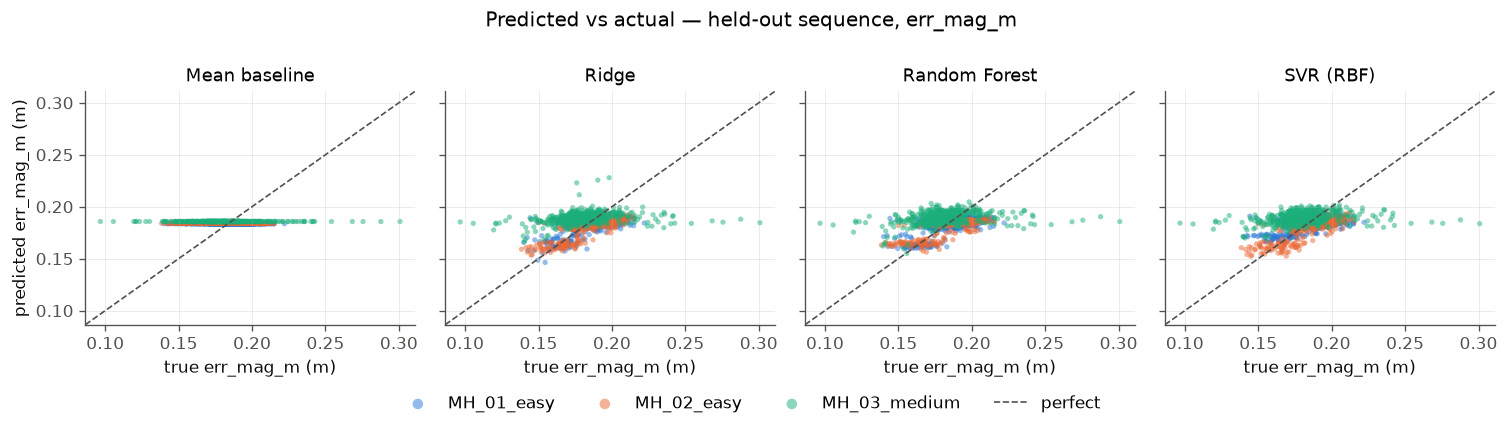

In [5]:
fig = plots.plot_pred_vs_actual(preds, TARGET); plt.show()

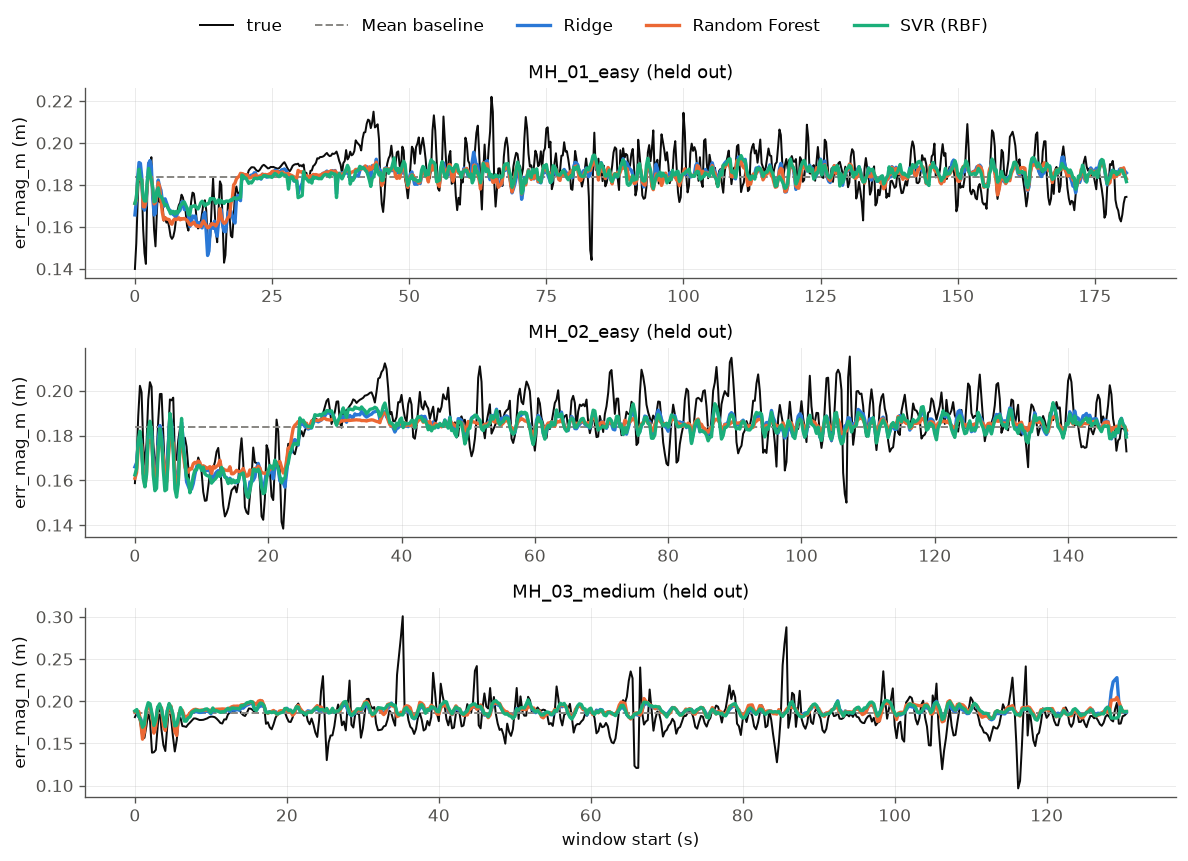

In [6]:
fig = plots.plot_error_over_time(preds, TARGET); plt.show()

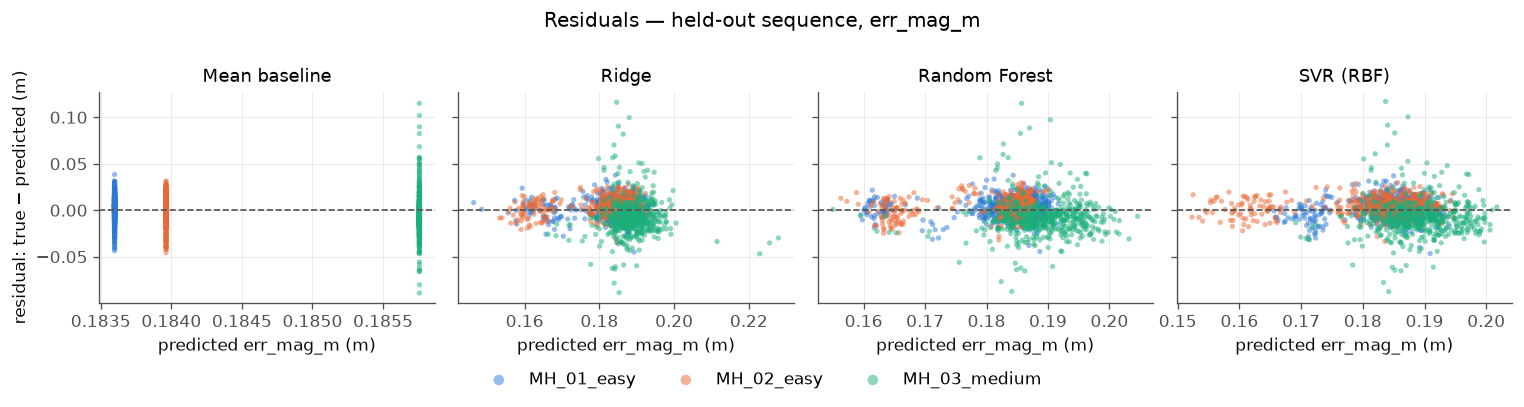

In [7]:
fig = plots.plot_residuals(preds, TARGET); plt.show()

## 3. Failure analysis

The aggregate hides two different stories. We look at **where** the error lives (sequence, time, motion level, individual windows) and **why**.

### 3a. Where models win on easy sequences: the opening regime

The time plot shows the first ~20 s of MH_01 and MH_02 sit at a lower drift level (~0.167 m) than the rest (~0.188 m). Splitting the error at that point:

In [8]:
rows = []
for seq in sequences[:2]:
    g = preds[preds["seq_id"] == seq].copy()
    g["t_s"] = (g["t_start_ns"] - g["t_start_ns"].min()) / 1e9
    g["segment"] = np.where(g["t_s"] < 20, "first 20 s", np.where(g["t_s"] >= 25, "after 25 s", "transition"))
    g["abs_err"] = (g["y_true"] - g["y_pred"]).abs()
    t = g[g["segment"] != "transition"].pivot_table(index="segment", columns="model", values="abs_err", aggfunc="mean")
    t.insert(0, "mean y_true", g[g["segment"] != "transition"].groupby("segment")["y_true"].mean())
    rows.append(t.assign(seq=seq))
pd.concat(rows).reset_index().set_index(["seq", "segment"])[["mean y_true", *MODEL_NAMES]].round(4)

model                  mean y_true    mean   ridge  random_forest     svr
seq        segment                                                       
MH_01_easy after 25 s       0.1883  0.0086  0.0079         0.0078  0.0081
           first 20 s       0.1669  0.0173  0.0071         0.0080  0.0084
MH_02_easy after 25 s       0.1891  0.0083  0.0072         0.0073  0.0071
           first 20 s       0.1686  0.0193  0.0084         0.0104  0.0091

Most of the gain is in the opening segment: there the features tell the models drift is lower, and they halve the baseline's error. After it, the models improve on the baseline only modestly — they track the general level but not the second-to-second fluctuations.

### 3b. Where models fail: MH_03_medium is out of distribution

When MH_03 is held out, the models train on the two easy flights only. MH_03 moves differently: faster rotation and more jerk, and its label is far more spread out, with spikes up to 0.30 m.

In [9]:
shift_feats = ["gyro_mag_mean", "jerk_mag_mean", "ax_mean", "ax_rms"]
rows = []
for fold in folds:
    train, test = fold_frames(df, fold)
    for f in shift_feats:
        out = ((test[f] < train[f].min()) | (test[f] > train[f].max())).mean()
        rows.append({"test_seq": fold.test[0], "feature": f,
                     "train_mean": train[f].mean(), "test_mean": test[f].mean(),
                     "test_outside_train_range_%": 100 * out})
display(pd.DataFrame(rows).pivot(index="feature", columns="test_seq",
        values=["train_mean", "test_mean", "test_outside_train_range_%"]).round(3))
df.groupby("seq_id")[TARGET].agg(["std", "min", "max"]).round(4)

train_mean                          test_mean             \
test_seq      MH_01_easy MH_02_easy MH_03_medium MH_01_easy MH_02_easy   
feature                                                                  
ax_mean            9.101      9.170        9.054      9.118      8.977   
ax_rms             9.179      9.246        9.118      9.181      9.041   
gyro_mag_mean      0.250      0.248        0.213      0.215      0.211   
jerk_mag_mean    347.471    346.474      325.346    326.443    324.014   

                           test_outside_train_range_%                          
test_seq      MH_03_medium                 MH_01_easy MH_02_easy MH_03_medium  
feature                                                                        
ax_mean              9.242                      0.276      7.047        0.000  
ax_rms               9.336                      0.000      6.879        0.765  
gyro_mag_mean        0.295                      0.000      0.000        4.780  
jerk_mag_mean      374.203                      4.144      0.000        0.574

,std,min,max
seq_id,,,
MH_01_easy,0.0119,0.1399,0.2220
MH_02_easy,0.0131,0.1384,0.2153
MH_03_medium,0.0205,0.0967,0.3008


### 3c. Error broadly grows with rotation rate

Random Forest absolute error by quartile of the window's mean rotation rate (`gyro_mag_mean`), within each held-out sequence. The fastest-rotating quarter of windows has 25–65% more error than the slowest, though not in a steady staircase:

In [10]:
rf = preds[preds["model"] == "random_forest"].merge(
    df[["seq_id", "window_id", "gyro_mag_mean"]], on=["seq_id", "window_id"])
rf["abs_err"] = (rf["y_true"] - rf["y_pred"]).abs()
rf["rotation_quartile"] = rf.groupby("seq_id")["gyro_mag_mean"].transform(
    lambda s: pd.qcut(s, 4, labels=["Q1 slow", "Q2", "Q3", "Q4 fast"]))
rf.pivot_table(index="seq_id", columns="rotation_quartile", values="abs_err",
               aggfunc="mean", observed=True).round(4)

rotation_quartile,Q1 slow,Q2,Q3,Q4 fast
seq_id,,,,
MH_01_easy,0.0062,0.0074,0.0085,0.0087
MH_02_easy,0.0067,0.0071,0.0092,0.0084
MH_03_medium,0.0112,0.0161,0.0145,0.0183


### 3d. Error is concentrated in label spikes

A tenth of the windows carries roughly 30% of the error. Those are the windows where the true drift jumps away from its usual level, and the models — which predict a smooth level — miss them.

In [11]:
rows = []
for seq in sequences:
    g = rf[rf["seq_id"] == seq].sort_values("abs_err", ascending=False)
    k = len(g) // 10
    r = g["y_true"] - g["y_pred"]
    rows.append({
        "test_seq": seq,
        "share_of_abs_error_in_worst_10%": g["abs_err"].head(k).sum() / g["abs_err"].sum(),
        "corr(abs_err, |y - median y|)": np.corrcoef(g["abs_err"], (g["y_true"] - g["y_true"].median()).abs())[0, 1],
        "corr(pred, true)": np.corrcoef(g["y_true"], g["y_pred"])[0, 1],
        "bias^2 share of MSE": r.mean() ** 2 / (r ** 2).mean(),
    })
pd.DataFrame(rows).set_index("test_seq").round(3)

,share_of_abs_error_in_worst_10%,"corr(abs_err, |y - median y|)","corr(pred, true)",bias^2 share of MSE
test_seq,,,,
MH_01_easy,0.277,0.649,0.597,0.061
MH_02_easy,0.269,0.634,0.699,0.103
MH_03_medium,0.320,0.826,0.305,0.135


In [12]:
worst = rf.sort_values("abs_err", ascending=False).head(10).copy()
worst["t_s"] = (worst["t_start_ns"] - worst.groupby("seq_id")["t_start_ns"].transform("min")) / 1e9
worst[["seq_id", "window_id", "y_true", "y_pred", "abs_err", "gyro_mag_mean"]].round(4)

,seq_id,window_id,y_true,y_pred,abs_err,gyro_mag_mean
1461,MH_03_medium,141,0.3008,0.1857,0.1151,0.1988
1663,MH_03_medium,343,0.2877,0.1904,0.0973,0.1830
1460,MH_03_medium,140,0.2756,0.1870,0.0886,0.2284
1785,MH_03_medium,465,0.0967,0.1841,0.0874,0.1971
1662,MH_03_medium,342,0.2682,0.1855,0.0827,0.1365
1786,MH_03_medium,466,0.1056,0.1824,0.0768,0.2432
1459,MH_03_medium,139,0.2541,0.1827,0.0713,0.3012
1584,MH_03_medium,264,0.1208,0.1862,0.0654,0.5505
1585,MH_03_medium,265,0.1210,0.1849,0.0639,0.6758
1583,MH_03_medium,263,0.1234,0.1856,0.0622,0.4084


**Why.** The prediction/truth correlation drops from 0.60–0.70 on the easy flights to about 0.31 on MH_03, and a constant offset (bias²) explains only 6–14% of the squared error. So the failure is mostly *not* a simple calibration shift that could be fixed by adding a constant: the models cannot see the spikes coming from window-level summary statistics.

### 3e. Which features carry the signal (held-out permutation importance)

Increase in held-out MAE when one feature is shuffled, averaged over folds. Accelerometer level features (`ax_mean`, `ax_rms`, and for SVR `acc_mag_mean`) dominate both models, matching notebook 04 — consistent with the label being driven largely by how gravity and accelerometer bias project into the integration.

In [13]:
perm = importance[importance["kind"] == "permutation"]
top = (perm.groupby(["model", "feature"])["importance"].mean().mul(1000)
       .rename("MAE increase (mm)").reset_index()
       .sort_values("MAE increase (mm)", ascending=False).groupby("model").head(8))
top.set_index(["model", "feature"]).round(3)

MAE increase (mm)
model         feature                           
svr           acc_mag_mean                 0.309
              ax_mean                      0.291
              ax_rms                       0.278
random_forest ax_mean                      0.244
              ax_rms                       0.159
svr           gy_mean                      0.067
              ax_skew                      0.067
random_forest az_zcr                       0.052
svr           ax_spec_entropy              0.051
              az_spec_entropy              0.043
random_forest az_mean                      0.041
svr           jerk_az_rms                  0.040
random_forest ay_zcr                       0.035
              az_rms                       0.032
              acc_mag_mean                 0.028
              ay_mean                      0.025

### 3f. Bias-corrected target (oracle comparison)

The same pipeline on `err_mag_m_bc`, the drift left after subtracting the dataset's own bias estimates (`results/metrics/err_mag_m_bc.csv`). R² is near zero (at most 0.05) on every fold and negative on average: once bias is removed, the remaining drift is barely predictable from these motion features.

In [14]:
print("MAE (m)"); display(table(metrics_bc, "mae").round(4))
print("R^2"); display(table(metrics_bc, "r2").round(3))

MAE (m)


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,0.0103,0.0109,0.0154,0.0122
ridge,0.0095,0.0102,0.0148,0.0115
random_forest,0.0092,0.0093,0.0143,0.0109
svr,0.0089,0.0087,0.0154,0.0110


R^2


test_seq,MH_01_easy,MH_02_easy,MH_03_medium,mean over folds
model,,,,
mean,-0.038,-0.393,-0.186,-0.206
ridge,0.023,-0.302,-0.106,-0.128
random_forest,0.004,-0.146,-0.082,-0.075
svr,0.051,-0.037,-0.216,-0.067


## What we learned

* **Easy sequences: real but modest skill.** All three models beat the mean baseline on MH_01 and MH_02. Most of that comes from recognising the low-drift opening ~20 s; after it the gains are small.
* **MH_03_medium: failure from distribution shift.** Trained only on the easy flights, the models face faster rotation (mean `gyro_mag_mean` about 0.30 vs 0.21 rad/s) and a label with about 1.6× the spread (std 0.0205 vs ~0.0125 m) and spikes to 0.30 m. No model beats the mean there; error broadly grows with rotation rate.
* **Spikes are the residual problem.** About 30% of the error sits in the worst 10% of windows, where the drift jumps. Window summaries do not anticipate them, and the error is not a constant offset that recalibration could remove.
* **Model choice matters little.** Ridge, Random Forest and SVR are within ~0.0002 m mean MAE of each other. A regularised linear model is as good as the non-linear ones on this data.
* **Implication for Phase 2.** Better features or models alone are unlikely to fix MH_03; more varied training flights (MH_04/MH_05) and sequence models that see the raw 200×6 signal are the natural next steps.